# 01 — Exploration et audit des données

**Objectif** : comprendre les données brutes des DPE (logements existants et neufs, Corse) avant toute modélisation, et repérer ce qu'il faudra traiter.

**Ce notebook est un audit descriptif.** Il mesure la qualité des données (valeurs manquantes, doublons, valeurs aberrantes, cohérence de la règle de l'étiquette) et compare les deux jeux. Il ne modifie aucune donnée et ne fixe aucune liste finale de variables.

**Règle de rigueur** : tout ce qui sert à *décider* de la modélisation à partir de la cible (corrélations avec la cible, importance des variables, sélection, imputation, standardisation) est fait dans le notebook `03`, **sur le jeu d'entraînement uniquement**, après le découpage train/test. Ici, les statistiques portent sur l'ensemble pour décrire la qualité des données, pas pour entraîner quoi que ce soit.

**Prérequis** : avoir exécuté `python -m src.data.extraction` (fichiers `data/raw/dpe_existant.csv` et `data/raw/dpe_neuf.csv`).

## 0. Préparation

In [17]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Le notebook est dans notebooks/ : on ajoute la racine du projet au chemin Python.
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

from src.utilis import config
from src.utilis import regles_dpe

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (9, 4.5)

DOSSIER_FIG = config.RACINE / "reports" / "figures"
ORDRE = config.ORDRE_ETIQUETTES
CONSO = config.CIBLE_REGRESSION
ETIQ = config.CIBLE_CLASSIFICATION
GES = config.GES_PAR_M2


def sauver(fig, nom):
    """Enregistre la figure dans reports/figures pour le rapport."""
    DOSSIER_FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(DOSSIER_FIG / f"{nom}.png", dpi=150, bbox_inches="tight")

## 1. Chargement

In [ ]:
fichiers = {nom: config.DATA_BRUT / f"dpe_{nom}.csv" for nom in config.DATASETS}
absents = [str(p) for p in fichiers.values() if not p.exists()]
if absents:
    raise FileNotFoundError(f"Fichiers introuvables : {absents}. Lancer d'abord l'extraction.")

# concaténation des fichiers CSV en un seul DataFrame
df = pd.concat(
    [pd.read_csv(chemin, low_memory=False) for chemin in fichiers.values()],
    ignore_index=True,
)
print(f"{len(df):,} lignes x {df.shape[1]} colonnes")
print(df["source_jeu"].value_counts().to_string())
print(f"Mémoire : {df.memory_usage(deep=True).sum() / 1e6:.1f} Mo")

59,702 lignes x 36 colonnes
source_jeu
existant    54399
neuf         5303
Mémoire : 106.8 Mo


In [ ]:
# vérification du dataframe
df.head(3).T

,0,1,2
etiquette_dpe,C,E,D
conso_5_usages_par_m2_ep,179.00,307.00,223.30
emission_ges_5_usages_par_m2,7.00,12.00,8.00
etiquette_ges,B,C,B
surface_habitable_logement,87.20,60.60,33.10
hauteur_sous_plafond,3.10,2.50,2.50
annee_construction,NaN,"1,970.00","2,001.00"
nombre_niveau_logement,1.00,1.00,1.00
type_batiment,appartement,maison,maison
periode_construction,1948-1974,1948-1974,2001-2005


* vérification des type

In [5]:
print(df.dtypes.value_counts().to_string())
print()
print("Colonnes de type texte :", df.select_dtypes(exclude="number").columns.tolist())

str        26
float64     9
int64       1

Colonnes de type texte : ['etiquette_dpe', 'etiquette_ges', 'type_batiment', 'periode_construction', 'qualite_isolation_murs', 'qualite_isolation_menuiseries', 'qualite_isolation_plancher_bas', 'qualite_isolation_enveloppe', 'type_energie_principale_chauffage', 'type_installation_chauffage', 'type_energie_principale_ecs', 'type_ventilation', 'zone_climatique', 'classe_altitude', 'classe_inertie_batiment', 'numero_dpe', 'date_reception_dpe', 'date_etablissement_dpe', 'date_derniere_modification_dpe', 'methode_application_dpe', 'adresse_ban', 'code_departement_ban', 'nom_commune_ban', '_geopoint', 'statut_geocodage', 'source_jeu']


## 2. Comparaison des schémas neuf / existant

`extraction.py` ne demande que les colonnes présentes dans chaque jeu. Une colonne entièrement vide pour une source est donc soit absente de ce jeu, soit jamais renseignée. Cela détermine ce qu'on pourra réellement concaténer.

In [6]:
manq_par_source = (
    df.drop(columns="source_jeu").isna().groupby(df["source_jeu"]).mean().T
)

for source in manq_par_source.columns:
    vides = manq_par_source.index[manq_par_source[source] == 1].tolist()
    print(f"{source} : {len(vides)} colonne(s) entièrement vide(s) -> {vides}")

existant : 0 colonne(s) entièrement vide(s) -> []
neuf : 0 colonne(s) entièrement vide(s) -> []


In [7]:
if manq_par_source.shape[1] == 2:
    a, b = manq_par_source.columns
    ecart = (manq_par_source[a] - manq_par_source[b]).abs()
    print("Colonnes dont le taux de manquants diffère de plus de 30 points entre les deux jeux :")
    display(
        manq_par_source.loc[ecart > 0.3]
        .assign(ecart=ecart)
        .sort_values("ecart", ascending=False)
    )

Colonnes dont le taux de manquants diffère de plus de 30 points entre les deux jeux :


source_jeu,existant,neuf,ecart
classe_inertie_batiment,0.02,0.98,0.97
type_ventilation,0.05,0.98,0.94
logement_traversant,0.23,0.73,0.49
annee_construction,0.43,0.00,0.43
nombre_niveau_logement,0.02,0.35,0.32


## 3. Qualité des données

### 3.1 DPE de test
Certains enregistrements sont des exemples (adresses « Les Exemples »). On les repère sans les supprimer : il faut d'abord vérifier à l'œil que le motif ne touche pas de vraies adresses (un mot comme « test » peut apparaître dans un nom de rue).

In [8]:
motif = "|".join(config.MOTS_DPE_TEST)
est_test = df["adresse_ban"].fillna("").str.contains(motif, case=False, regex=True)
print(f"Adresses contenant {config.MOTS_DPE_TEST} : {est_test.sum()} ({est_test.mean():.2%})")
df.loc[est_test, ["numero_dpe", "adresse_ban", ETIQ, "source_jeu"]].head(15)

Adresses contenant ('exemple', 'test') : 36 (0.06%)


,numero_dpe,adresse_ban,etiquette_dpe,source_jeu
848,2120E0081527L,Santa Lucia Di Testa 20137 Lecci,B,existant
893,2120E0081568A,Santa Lucia Di Testa 20137 Lecci,B,existant
2185,2120E0863564U,Testa 20124 Zonza,E,existant
4658,2220E0391641Y,Route de Piedirosa - Testaccia 20230 Linguizzetta,C,existant
6800,2220E1737372V,Route de Piedirosa - Testaccia 20230 Linguizzetta,C,existant
8402,2220E2540927U,Route de Piedirosa - Testaccia 20230 Linguizzetta,E,existant
10422,2220E3121881E,Route de Piedirosa - Testaccia 20230 Linguizzetta,F,existant
10827,2220E2701196Z,Route de Piedirosa - Testaccia 20230 Linguizzetta,C,existant
15122,2320E0167628C,Route de Piedirosa - Testaccia 20230 Linguizzetta,F,existant
15549,2320E4133562A,Route de Piedirosa - Testaccia 20230 Linguizzetta,B,existant


### 3.2 Doublons
Un même numéro de DPE ne devrait apparaître qu'une fois. Un même logement peut aussi avoir plusieurs DPE successifs (la date de dernière modification peut aider à garder le plus récent). Le test sur « adresse + surface » est seulement indicatif : plusieurs logements différents d'un même immeuble peuvent légitimement se ressembler.

In [9]:
dup_num = df["numero_dpe"].duplicated(keep=False)
print(f"Lignes dont le numero_dpe apparaît plusieurs fois : {dup_num.sum()}")

cle = [c for c in ["adresse_ban", "surface_habitable_logement"] if c in df.columns]
base = df.dropna(subset=cle)
dup_log = base.duplicated(subset=cle, keep=False)
print(f"Lignes partageant {cle} avec une autre ligne : {dup_log.sum()}")
colonnes_vue = ["numero_dpe", "date_reception_dpe", ETIQ] + cle
base.loc[dup_log, colonnes_vue].sort_values(cle).head(10)

Lignes dont le numero_dpe apparaît plusieurs fois : 0
Lignes partageant ['adresse_ban', 'surface_habitable_logement'] avec une autre ligne : 23893


,numero_dpe,date_reception_dpe,etiquette_dpe,adresse_ban,surface_habitable_logement
32671,2520E1417761F,2025-04-26,D,1 A Licciola 20231 Venaco,73.60
33567,2520E1417782A,2025-04-26,D,1 A Licciola 20231 Venaco,73.60
3137,2220E0766615A,2022-04-12,B,1 Avenue Piccioni 20220 L'Ã le-Rousse,119.20
3524,2220E0766747C,2022-04-12,B,1 Avenue Piccioni 20220 L'Ã le-Rousse,119.20
3715,2220E0766606R,2022-04-12,B,1 Avenue Piccioni 20220 L'Ã le-Rousse,119.20
14252,2320E1337181X,2023-04-21,D,1 Boulevard Benoite Danesi 20200 Bastia,52.00
14560,2320E1493048U,2023-05-05,D,1 Boulevard Benoite Danesi 20200 Bastia,52.00
11425,2320E0395449L,2023-02-07,E,1 Carrefour Jean Nicoli 20250 Corte,39.00
12549,2320E0395446I,2023-02-07,E,1 Carrefour Jean Nicoli 20250 Corte,39.00
34199,2520E0714154K,2025-03-03,D,1 Casale di l'Ondari 20260 Lumio,137.40


### 3.3 Dates, méthodes et versions du DPE

                  min        max  count
source_jeu                             
existant   2021-07-01 2026-11-10  54399
neuf       2021-07-14 2026-10-22   5303


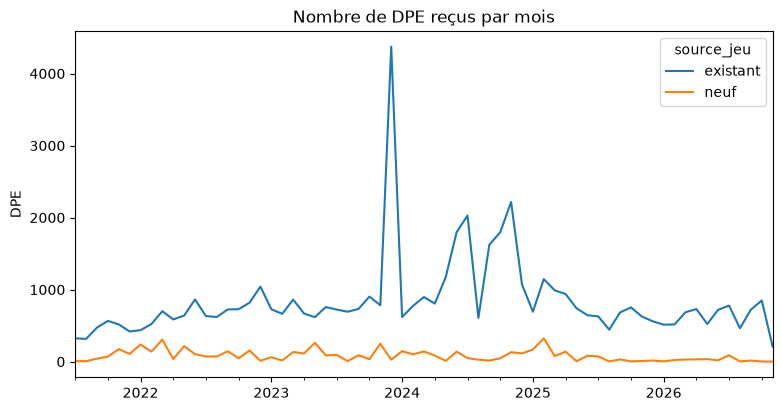

In [10]:
for col in ["date_reception_dpe", "date_etablissement_dpe", "date_derniere_modification_dpe"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print(df.groupby("source_jeu")["date_reception_dpe"].agg(["min", "max", "count"]).to_string())

mensuel = (
    df.dropna(subset=["date_reception_dpe"])
    .groupby([pd.Grouper(key="date_reception_dpe", freq="MS"), "source_jeu"])
    .size()
    .unstack(fill_value=0)
)
fig, ax = plt.subplots()
mensuel.plot(ax=ax)
ax.set_title("Nombre de DPE reçus par mois")
ax.set_xlabel("")
ax.set_ylabel("DPE")
sauver(fig, "01_dpe_par_mois")
plt.show()

In [11]:
for col in ["methode_application_dpe", "version_dpe"]:
    if col in df.columns:
        print(pd.crosstab(df[col], df["source_jeu"]).to_string(), "\n")

source_jeu                                                                                     existant  neuf
methode_application_dpe                                                                                      
dpe appartement généré à partir des données DPE immeuble                                           9353   699
dpe appartement individuel                                                                        30912    12
dpe immeuble collectif                                                                             1162    17
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : appartement                 0    25
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : immeuble                    0     5
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : maison individuelle         0   143
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : appartement                            0  3208
dpe issu d

## 4. Valeurs manquantes
On regarde d'abord les variables candidates définies dans `config.py`. Le seuil à partir duquel on écarte une colonne ne se décide pas ici : il sera justifié dans le notebook `03`.

In [12]:
manq = df.isna().mean().sort_values(ascending=False).rename("taux_manquants")
candidates = [c for c in config.VARIABLES_CANDIDATES if c in df.columns]
absentes = [c for c in config.VARIABLES_CANDIDATES if c not in df.columns]
if absentes:
    print("Candidates absentes des données :", absentes)

tab = manq.loc[candidates].to_frame()
tab["type"] = [
    "numérique" if c in config.VARIABLES_CANDIDATES_NUMERIQUES else "catégorielle"
    for c in tab.index
]
tab = tab.join(manq_par_source.add_prefix("manq_")).sort_values("taux_manquants", ascending=False)

config.DATA_TRAITE.mkdir(parents=True, exist_ok=True)
tab.to_csv(config.DATA_TRAITE / "audit_manquants_candidates.csv")
tab

,taux_manquants,type,manq_existant,manq_neuf
annee_construction,0.39,numérique,0.43,0.00
logement_traversant,0.28,catégorielle,0.23,0.73
type_installation_chauffage,0.24,catégorielle,0.24,0.25
type_ventilation,0.13,catégorielle,0.05,0.98
classe_inertie_batiment,0.10,catégorielle,0.02,0.98
qualite_isolation_plancher_bas,0.08,catégorielle,0.08,0.00
nombre_niveau_logement,0.05,numérique,0.02,0.35
surface_habitable_logement,0.02,numérique,0.02,0.03
zone_climatique,0.02,catégorielle,0.00,0.24
classe_altitude,0.02,catégorielle,0.00,0.24


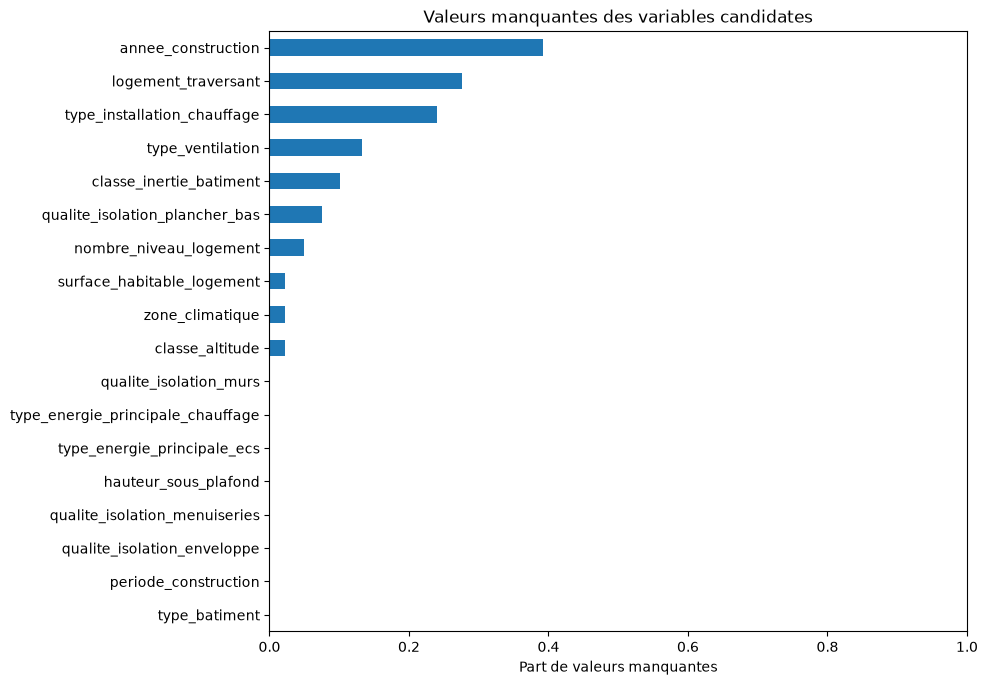

In [13]:
fig, ax = plt.subplots(figsize=(9, 0.35 * len(tab) + 1.5))
tab["taux_manquants"].sort_values().plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel("Part de valeurs manquantes")
ax.set_title("Valeurs manquantes des variables candidates")
sauver(fig, "01_manquants_candidates")
plt.show()

## 5. Variables cibles

Valeurs d'étiquette inattendues : aucune
source_jeu     existant  neuf
etiquette_dpe                
A                  6363  4379
B                  8937   564
C                 24534   357
D                  8853     1
E                  3504     0
F                  1517     1
G                   691     1

source_jeu     existant  neuf
etiquette_dpe                
A                 11.70 82.60
B                 16.40 10.60
C                 45.10  6.70
D                 16.30  0.00
E                  6.40  0.00
F                  2.80  0.00
G                  1.30  0.00


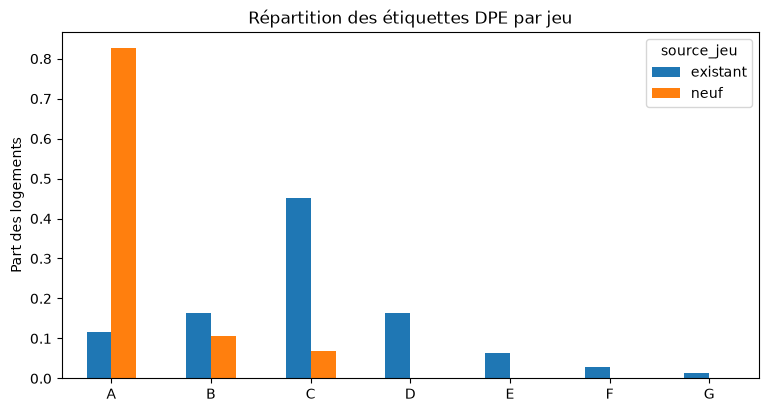

In [14]:
inattendues = set(df[ETIQ].dropna().unique()) - set(ORDRE)
print("Valeurs d'étiquette inattendues :", inattendues or "aucune")

effectifs = pd.crosstab(df[ETIQ], df["source_jeu"]).reindex(ORDRE).fillna(0).astype(int)
parts = effectifs / effectifs.sum()
print(effectifs.to_string())
print()
print((parts * 100).round(1).to_string())

fig, ax = plt.subplots()
parts.plot.bar(ax=ax, rot=0)
ax.set_title("Répartition des étiquettes DPE par jeu")
ax.set_ylabel("Part des logements")
ax.set_xlabel("")
sauver(fig, "01_repartition_etiquettes")
plt.show()

source_jeu  existant     neuf
count      54,398.00 5,303.00
mean          146.41    41.46
std            84.89    36.59
min            17.70     2.30
1%             31.00    18.40
50%           129.00    40.00
99%           446.31    79.50
max         1,150.00 2,523.40

Asymétrie (skewness) : 1.98


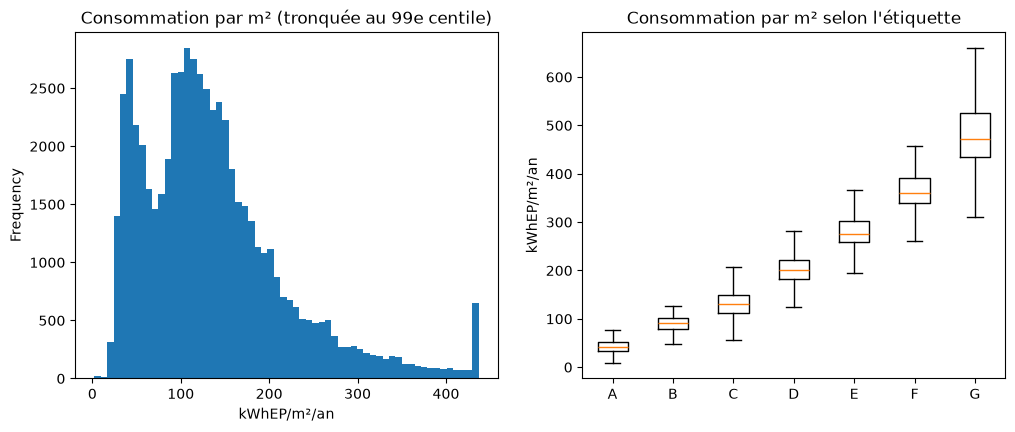

In [15]:
print(df.groupby("source_jeu")[CONSO].describe(percentiles=[0.01, 0.5, 0.99]).T.to_string())
print(f"\nAsymétrie (skewness) : {df[CONSO].skew():.2f}")

haut = df[CONSO].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df[CONSO].dropna().clip(upper=haut).plot.hist(bins=60, ax=axes[0])
axes[0].set_title("Consommation par m² (tronquée au 99e centile)")
axes[0].set_xlabel("kWhEP/m²/an")

groupes = [df.loc[df[ETIQ] == lettre, CONSO].dropna() for lettre in ORDRE]
axes[1].boxplot(groupes, showfliers=False)
axes[1].set_xticks(range(1, len(ORDRE) + 1))
axes[1].set_xticklabels(ORDRE)
axes[1].set_title("Consommation par m² selon l'étiquette")
axes[1].set_ylabel("kWhEP/m²/an")
sauver(fig, "01_conso_par_etiquette")
plt.show()

In [18]:
print(df[GES].describe(percentiles=[0.01, 0.5, 0.99]).to_string())
print()
print(df["etiquette_ges"].value_counts(dropna=False).reindex(ORDRE + [np.nan]).to_string())

count   59,701.00
mean        10.14
std         12.83
min          0.00
1%           1.00
50%          5.30
99%         64.00
max        172.00

etiquette_ges
A     32,028.00
B     11,455.00
C     12,040.00
D      2,962.00
E        832.00
F        294.00
G         91.00
NaN         NaN


## 6. Vérification de la règle de l'étiquette
On recalcule l'étiquette à partir des seuils de `config.py` (consommation en énergie primaire et GES, la plus défavorable des deux classes) et on la compare à `etiquette_dpe`. Un accord proche de 100 % confirme la règle, et donc le risque de fuite de données si ces colonnes servaient de variables. Les désaccords révèlent des cas particuliers ou des seuils à corriger.

In [19]:
d = df.dropna(subset=[ETIQ, CONSO, GES]).copy()
d["etiquette_calculee"] = regles_dpe.etiquette_theorique(d[CONSO], d[GES])
d["accord"] = d["etiquette_calculee"] == d[ETIQ]

print(f"Lignes comparées : {len(d):,} sur {len(df):,}")
print(f"Accord global : {d['accord'].mean():.2%}")
print(d.groupby("source_jeu")["accord"].mean().map("{:.2%}".format).to_string())

Lignes comparées : 59,701 sur 59,702
Accord global : 95.43%
source_jeu
existant    95.15%
neuf        98.28%


In [20]:
ecarts = d.loc[~d["accord"]]
print(f"Désaccords : {len(ecarts):,}")
if len(ecarts):
    print("\nÉtiquette réelle (lignes) contre étiquette recalculée (colonnes) :")
    display(
        pd.crosstab(ecarts[ETIQ], ecarts["etiquette_calculee"])
        .reindex(index=ORDRE, columns=ORDRE, fill_value=0)
    )
    surface = "surface_habitable_logement"
    if surface in d.columns:
        print("\nSurface selon l'accord (les petites surfaces ont-elles des seuils différents ?) :")
        print(d.groupby("accord")[surface].describe().to_string())
    if "version_dpe" in d.columns:
        print("\nAccord selon la version du DPE :")
        display(pd.crosstab(d["version_dpe"], d["accord"], normalize="index"))

Désaccords : 2,730

Étiquette réelle (lignes) contre étiquette recalculée (colonnes) :


etiquette_calculee,A,B,C,D,E,F,G
etiquette_dpe,,,,,,,
A,0,40,0,0,0,0,0
B,40,0,149,0,0,0,0
C,10,475,0,902,18,0,0
D,7,9,374,0,323,17,0
E,5,5,9,37,0,136,36
F,0,1,14,8,9,0,92
G,2,4,1,1,2,4,0



Surface selon l'accord (les petites surfaces ont-elles des seuils différents ?) :
           count  mean   std  min   25%   50%   75%      max
accord                                                      
False   2,697.00 42.67 32.51 8.00 22.10 29.20 63.00   379.00
True   55,653.00 78.85 59.66 5.20 49.30 68.60 87.50 2,717.10

Accord selon la version du DPE :


accord,False,True
version_dpe,,
1.00,0.10,0.90
1.10,0.05,0.95
2.00,0.02,0.98
2.10,0.03,0.97
2.20,0.05,0.95
2.30,0.05,0.95
2.40,0.04,0.96
2.50,0.04,0.96
2.60,0.05,0.95


In [21]:
rang = {lettre: i for i, lettre in enumerate(ORDRE)}
rang_energie = regles_dpe.etiquette_energie(d[CONSO]).map(rang)
rang_ges = regles_dpe.etiquette_ges(d[GES]).map(rang)
rang_ges = pd.Series(rang_ges.values, index=rang_energie.index)

print(f"Énergie plus défavorable que GES (l'énergie décide) : {(rang_energie > rang_ges).mean():.1%}")
print(f"GES plus défavorable que l'énergie (les GES décident) : {(rang_ges > rang_energie).mean():.1%}")
print(f"Les deux classes sont identiques : {(rang_energie == rang_ges).mean():.1%}")

Énergie plus défavorable que GES (l'énergie décide) : 58.8%
GES plus défavorable que l'énergie (les GES décident) : 13.8%
Les deux classes sont identiques : 27.4%


## 7. Variables candidates

### 7.1 Variables numériques
Les seuils de contrôle ci-dessous sont des repères de bon sens, à discuter en équipe : ils signalent des valeurs à examiner, pas à supprimer d'office.

In [22]:
num = [c for c in config.VARIABLES_CANDIDATES_NUMERIQUES if c in df.columns]
for c in num:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df[num].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
surface_habitable_logement,"58,351.00",77.18,59.17,5.20,19.85,27.00,67.70,163.50,269.05,"2,717.10"
hauteur_sous_plafond,"59,702.00",2.59,1.93,1.30,2.30,2.50,2.50,3.00,3.40,307.70
annee_construction,"36,267.00","1,990.61",32.06,"1,300.00","1,900.00","1,948.00","1,995.00","2,023.00","2,025.00","2,027.00"
nombre_niveau_logement,"56,706.00",1.29,0.96,1.00,1.00,1.00,1.00,3.00,5.00,71.00


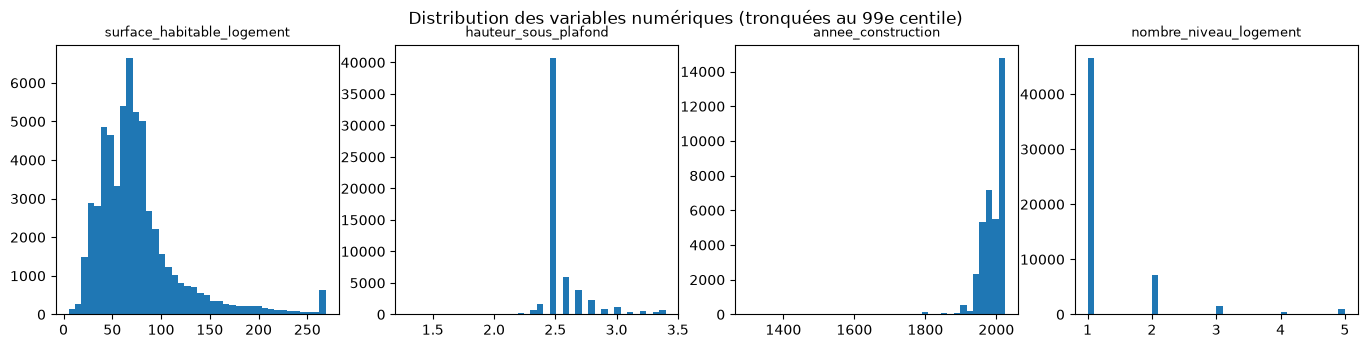

In [23]:
fig, axes = plt.subplots(1, len(num), figsize=(4.2 * len(num), 3.5))
for ax, c in zip(np.atleast_1d(axes), num):
    s = df[c].dropna()
    ax.hist(s.clip(upper=s.quantile(0.99)), bins=40)
    ax.set_title(c, fontsize=9)
fig.suptitle("Distribution des variables numériques (tronquées au 99e centile)")
sauver(fig, "01_distribution_numeriques")
plt.show()

In [24]:
annee_courante = pd.Timestamp.today().year
controles = {
    "surface_habitable_logement <= 0": ("surface_habitable_logement", lambda s: s <= 0),
    "surface_habitable_logement > 500 m²": ("surface_habitable_logement", lambda s: s > 500),
    "hauteur_sous_plafond < 1,8 m": ("hauteur_sous_plafond", lambda s: s < 1.8),
    "hauteur_sous_plafond > 5 m": ("hauteur_sous_plafond", lambda s: s > 5),
    "annee_construction < 1700 ou future": ("annee_construction", lambda s: (s < 1700) | (s > annee_courante)),
}
for nom, (colonne, regle) in controles.items():
    if colonne in df.columns:
        print(f"{nom} : {int(regle(df[colonne]).sum())} ligne(s)")

surface_habitable_logement <= 0 : 0 ligne(s)
surface_habitable_logement > 500 m² : 76 ligne(s)
hauteur_sous_plafond < 1,8 m : 10 ligne(s)
hauteur_sous_plafond > 5 m : 32 ligne(s)
annee_construction < 1700 ou future : 13 ligne(s)


### 7.2 Variables catégorielles

In [25]:
cat = [c for c in config.VARIABLES_CANDIDATES_CATEGORIELLES if c in df.columns]
resume = pd.DataFrame({
    "modalites": df[cat].nunique(),
    "manquants": df[cat].isna().mean(),
    "modalite_dominante": [df[c].mode().iat[0] if df[c].notna().any() else None for c in cat],
    "part_dominante": [
        df[c].value_counts(normalize=True).iat[0] if df[c].notna().any() else np.nan for c in cat
    ],
    "modalites_rares_sous_1pct": [(df[c].value_counts(normalize=True) < 0.01).sum() for c in cat],
}, index=cat).sort_values("modalites", ascending=False)
resume

,modalites,manquants,modalite_dominante,part_dominante,modalites_rares_sous_1pct
type_ventilation,38,0.13,Ventilation par ouverture des fenêtres,0.22,26
type_energie_principale_chauffage,13,0.00,Électricité,0.74,9
periode_construction,10,0.00,1948-1974,0.21,0
type_energie_principale_ecs,10,0.00,Électricité,0.66,6
zone_climatique,8,0.02,H3,0.99,7
qualite_isolation_murs,4,0.00,insuffisante,0.45,0
classe_inertie_batiment,4,0.10,Moyenne,0.39,0
qualite_isolation_enveloppe,4,0.00,insuffisante,0.52,0
qualite_isolation_menuiseries,4,0.00,moyenne,0.47,0
qualite_isolation_plancher_bas,4,0.08,très bonne,0.39,0


In [26]:
for c in ["type_ventilation", "periode_construction", "type_energie_principale_chauffage"]:
    if c in df.columns:
        print(f"--- {c} ---")
        print(df[c].value_counts(dropna=False).head(12).to_string(), "\n")

--- type_ventilation ---
type_ventilation
Ventilation par ouverture des fenêtres                   11638
NaN                                                       7897
VMC SF Hygro B après 2012                                 6756
VMC SF Auto réglable de 1982 à 2000                       5143
Ventilation naturelle par conduit                         4115
Ventilation par entrées d'air hautes et basses            4067
VMC SF Auto réglable après 2012                           3744
VMC SF Auto réglable de 2001 à 2012                       3398
VMC SF Hygro A après 2012                                 2543
Ventilation mécanique sur conduit existant avant 2013     2018
VMC SF Auto réglable avant 1982                           1927
VMC SF Hygro A de 2001 à 2012                             1834 

--- periode_construction ---
periode_construction
1948-1974     12714
2013-2021      9975
avant 1948     6619
2006-2012      6544
1989-2000      5438
après 2021     5251
1978-1982      4136
1983-1988 

## 8. Relations descriptives
Simples tableaux et graphiques pour se faire une idée. Ce ne sont pas des critères de sélection : celle-ci se fait sur le train, dans le notebook `03`.

In [27]:
for c in ["type_batiment", "type_energie_principale_chauffage", "zone_climatique"]:
    if c in df.columns:
        print(f"--- consommation par m² selon {c} ---")
        t = df.groupby(c)[CONSO].agg(["count", "median"]).sort_values("count", ascending=False)
        display(t.head(10))

--- consommation par m² selon type_batiment ---


,count,median
type_batiment,,
appartement,44209,119.00
maison,14157,131.40
immeuble,1335,133.60


--- consommation par m² selon type_energie_principale_chauffage ---


,count,median
type_energie_principale_chauffage,,
Électricité,44063,122.70
Gaz naturel,9713,116.30
GPL,2582,102.50
Bois – Bûches,1855,151.20
Fioul domestique,535,212.70
Réseau de Chauffage urbain,421,142.50
Propane,195,169.50
Bois – Granulés (pellets) ou briquettes,185,138.00
Non affecté,118,37.00


--- consommation par m² selon zone_climatique ---


,count,median
zone_climatique,,
H3,57774,123.60
H1a,280,174.10
H1c,98,150.65
H2d,67,108.80
H2c,65,156.80
H2b,49,207.20
H1b,40,89.90
H2a,21,161.00


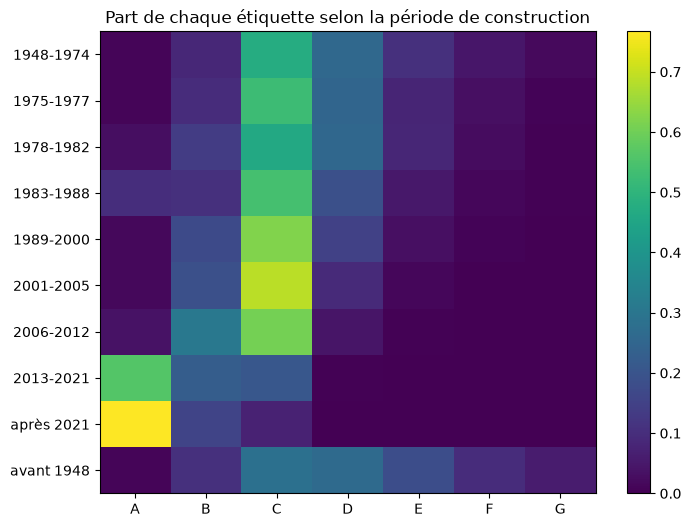

In [28]:
if "periode_construction" in df.columns:
    t = (
        pd.crosstab(df["periode_construction"], df[ETIQ], normalize="index")
        .reindex(columns=ORDRE)
        .fillna(0)
    )
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(t) + 2))
    image = ax.imshow(t.values, aspect="auto")
    ax.set_xticks(range(len(ORDRE)))
    ax.set_xticklabels(ORDRE)
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels(t.index)
    ax.set_title("Part de chaque étiquette selon la période de construction")
    fig.colorbar(image, ax=ax)
    sauver(fig, "01_etiquette_par_periode")
    plt.show()

## 9. Géographie
On vérifie que le filtre régional a bien fonctionné et que le géocodage est exploitable pour la carte de l'application. L'encadrement de la Corse (latitude 41,3 à 43,1 ; longitude 8,5 à 9,6) est approximatif.

In [29]:
print(df["code_departement_ban"].value_counts(dropna=False).to_string())

geo = df["_geopoint"].astype("string").str.split(",", expand=True)
if geo.shape[1] >= 2:
    df["lat"] = pd.to_numeric(geo[0], errors="coerce")
    df["lon"] = pd.to_numeric(geo[1], errors="coerce")
else:
    df["lat"] = np.nan
    df["lon"] = np.nan

print(f"\nSans coordonnées : {df['lat'].isna().mean():.2%}")
if "score_ban" in df.columns:
    print("\nQualité du géocodage (score_ban) :")
    print(df["score_ban"].describe().to_string())
if "statut_geocodage" in df.columns:
    print("\nStatut du géocodage :")
    print(df["statut_geocodage"].value_counts(dropna=False).to_string())

hors_corse = df["lat"].notna() & (~df["lat"].between(41.3, 43.1) | ~df["lon"].between(8.5, 9.6))
print(f"\nPoints hors de l'encadrement de la Corse : {int(hors_corse.sum())}")

code_departement_ban
2A    30716
2B    28986

Sans coordonnées : 0.00%

Qualité du géocodage (score_ban) :
count   59,702.00
mean         0.53
std          0.15
min          0.08
25%          0.42
50%          0.52
75%          0.60
max          0.98

Statut du géocodage :
statut_geocodage
adresse géocodée ban à l'adresse                              35120
adresse non géocodée ban car aucune correspondance trouvée    24582

Points hors de l'encadrement de la Corse : 0


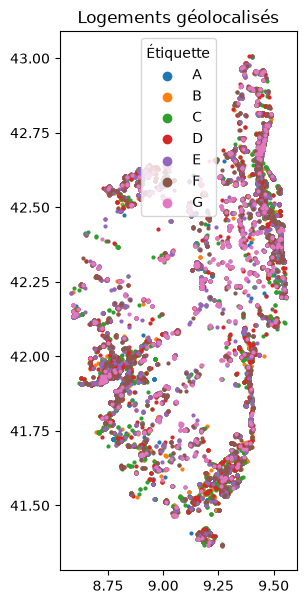

In [30]:
g = df.dropna(subset=["lat", "lon", ETIQ])
fig, ax = plt.subplots(figsize=(5.5, 7))
for lettre in ORDRE:
    sous = g[g[ETIQ] == lettre]
    ax.scatter(sous["lon"], sous["lat"], s=4, label=lettre)
ax.set_aspect(1 / np.cos(np.radians(g["lat"].mean())))
ax.legend(title="Étiquette", markerscale=3)
ax.set_title("Logements géolocalisés")
sauver(fig, "01_carte_logements")
plt.show()


## 10. Synthèse des constats

| Thème | Constat (chiffres) | Décision / suite |
|---|---|---|
| Volumes (existant / neuf) | 54 399 existants et 5 303 neufs, soit 59 702 lignes et 36 colonnes. | Conserver la provenance des données. |
| Schémas neuf / existant | Aucune colonne entièrement vide. Écarts importants de valeurs manquantes : inertie (2 % / 98 %), ventilation (5 % / 98 %), année de construction (43 % / 0 %). | Vérifier l'homogénéité des variables avant concaténation. |
| DPE de test | 36 adresses (0,06 %) correspondent aux mots « exemple » ou « test ». Plusieurs sont de vraies localités (Testa, Testaccia). | Affiner le filtre pour éviter les faux positifs. |
| Doublons | 0 doublon sur `numero_dpe`. 23 893 lignes partagent la même adresse et surface avec une autre ligne. | Examiner avant toute suppression. |
| Valeurs manquantes (candidates) | Année de construction : 39 % ; logement traversant : 28 % ; installation chauffage : 24 % ; ventilation : 13 % ; inertie : 10 %. | Étudier les causes et les traitements possibles. |
| Déséquilibre des étiquettes | Existants : C (45,1 %), A (11,7 %), G (1,3 %). Neufs : A (82,6 %), B (10,6 %), C (6,7 %). | Tenir compte du déséquilibre et des différences entre sources. |
| Règle de l'étiquette (accord) | 59 701 lignes comparées ; accord global : 95,43 % (95,15 % existants et 98,28 % neufs). 2 730 désaccords. | Approfondir les désaccords, notamment selon la surface et la version DPE. |
| Valeurs aberrantes | 76 surfaces > 500 m² ; 10 hauteurs < 1,8 m ; 32 hauteurs > 5 m ; 13 années de construction incohérentes. | Vérifier les observations sans suppression automatique. |
| Géocodage | 59 702 coordonnées présentes ; 35 120 adresses géocodées à l'adresse par la BAN et 24 582 sans correspondance. Score BAN moyen : 0,53. | Vérifier la qualité des coordonnées avant utilisation cartographique. |

**À reporter dans le notebook `03`** : périmètre final des lignes, règle de déduplication, colonnes trop vides à examiner, modalités à regrouper, variables à créer (feature engineering), contrôle neuf/existant avant concaténation.
